# Baseline candidates, expanded: longer baselines on the calibration block

`baseline_candidates.ipynb` restricted to the calibration block, with two longer baseline windows, [−1065, −66]
and [−565, −66] ms, added to the four previous ones. The calibration trials are the only trials stored with
enough pre-stimulus data for them (`_trial_raw.npy`, [−1100, 100] ms; the open-loop and intervention buffers start
at −210 ms), so the open-loop blocks are left out. Everything else is done as in `baseline_candidates.ipynb`: the
calibration is run once per candidate window, and the calibration outcomes, the dipoles and the sensor-space TEPs
of the calibration block are compared. The online code in `prime/decider/prime_core` is imported read-only. The
baseline is set on the notebook's own `Preprocessor` objects; no file in `prime/` is modified.

- **candidates**: every window in `CANDIDATES`, all on the same raw buffer `RAW_WINDOW` (default: the whole
  stored calibration trial, [−1100, 100] ms), so they differ only in the baseline. [−25, −15] ms is the online
  baseline on this longer buffer.
- **online**: the stored online calibration (bundle and dipole) on the online [−30, 100] ms buffer, as the
  reference.

The buffer is longer than in `baseline_candidates.ipynb` ([−200, 100] ms there). The ocular gate z-scores the
|source| of the eye components against a mean and SD taken over the whole buffer, so the buffer length alone moves
it: the four previous windows do not reproduce the numbers of `baseline_candidates.ipynb`. With
`RAW_WINDOW = (-0.200, 0.100)` and the four previous windows, this notebook reproduces them.

Only the post-stimulus side of the calibration is replayed: `Preprocessor.calibrate()` →
`DipoleFitter.calibrate()` → `TEPNormalizer.calibrate()`. The model (`OnlinePredictor`) is left out, so the
notebook needs no GPU and gives the same result on every machine.

| section | content |
|---|---|
| 0 | parameters |
| 1 | setup, completeness check |
| 2 | calibration per candidate; calibration epochs |
| 3 | calibration outcomes across candidates |
| 4 | dipoles per candidate |
| 5 | dipole plots: positions, time windows |
| 6 | dipoles compared with the online dipole; bootstrap stability |
| 7 | sensor-space TEPs of the calibration block |

**Requirements.** `mne`, `mne-icalabel`, `omegaconf` (as the decider). About ten minutes per session: each
calibration takes about three times as long on the long buffer.

## 0 · Parameters

All paths follow from `SUBJECT_ID`. `RUN_ID = None` picks the run folder that holds
`prime/trials_intervention.csv`. The output folder is created when missing.

In [1]:
# ---------------------------------------------------------------- session
SUBJECT_ID = "pilot005"          # BIDS subject label, without "sub-"
SESSION_ID = "ses-prime"
RUN_ID     = None                # NeuroSimo run folder, e.g. "105"; None = the one folder with prime/trials_intervention.csv

# ---------------------------------------------------------------- candidate baseline windows (s)
CANDIDATES = [
    (-1.065, -0.066),            # new
    (-0.565, -0.066),            # new
    (-0.200, -0.066),
    (-0.165, -0.066),
    (-0.075, -0.066),
    (-0.025, -0.015),            # the online baseline, here on the long buffer
]
RAW_WINDOW = (-1.100, 0.100)     # s, raw buffer every candidate is processed on; must contain every window and lie
                                 # within the stored calibration trial (_trial_raw.npy, [-1100, 100] ms)

# ---------------------------------------------------------------- outputs
OUT_DIR      = None              # None: <Loop>/offline_baseline/sub-<ID>/baseline_candidates_expanded
SAVE_FIGURES = True              # PNGs in OUT_DIR/figures

# ---------------------------------------------------------------- TEP plots
ROI_CHANNELS   = ["C1", "C3", "FC1", "FC3", "CP1", "CP3"]      # left M1
SINGLE_CHANNEL = "Cz"
TOPO_WINDOW    = (0.038, 0.050)  # s, fixed topoplot window (the dipole search window)

# ---------------------------------------------------------------- dipole bootstrap
N_BOOT    = 200                  # resamples of the calibration trials per source; 0 skips the bootstrap
BOOT_SEED = 0

# ---------------------------------------------------------------- decider settings that changed between sessions
SESSION_OVERRIDES = {
    "pilot003": {"ocular_z_threshold": 2.0},   # ran before commit f4fd395 (2026-09-17: 2.0 -> 2.5)
    "pilot004": {"ocular_z_threshold": 2.0},
}

## 1 · Setup and completeness check

### 1.1 Setup

`prime/decider` goes on `sys.path` with `sys.dont_write_bytecode = True`, so nothing is written into `prime/`.
In memory only: `np.trapz` → `np.trapezoid` where NumPy ≥ 2.4 removed it (the bad-channel check still calls
it), and `SESSION_OVERRIDES`.

`RAW_WINDOW` has to lie within the stored calibration trial ([−1100, 100] ms) and end at 100 ms. Every candidate
has to lie inside `RAW_WINDOW` and end before the artifact window (−14 ms). It may start on the buffer's first
sample: `preprocess_post()` resamples 5 kHz → 1 kHz with reflection padding, which changes only the first
resampled sample.

In [2]:
import contextlib, io, json, os, platform, sys, textwrap, time, warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats

warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
})
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 200)

if not hasattr(np, "trapz"):     # NumPy >= 2.4 removed np.trapz; Preprocessor.calibrate() still calls it
    np.trapz = np.trapezoid      # (bad-channel AUC). Same function, new name; in memory only.


def _find_loop_root() -> Path:
    env = os.environ.get("LOOP_ROOT")
    candidates = [env] if env else []
    candidates += [r"D:\Linus\Loop", str(Path.home() / "Desktop" / "Loop")]
    for c in candidates:
        if c and (Path(c) / "BIDS").is_dir() and (Path(c) / "prime").is_dir():
            return Path(c)
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "BIDS").is_dir() and (d / "prime").is_dir():
            return d
    raise FileNotFoundError("Loop root not found; set the LOOP_ROOT environment variable.")


# ---------------------------------------------------------------- paths, all derived from SUBJECT_ID
LOOP_ROOT    = _find_loop_root()
PRIME_DIR    = LOOP_ROOT / "prime"
DECIDER_DIR  = PRIME_DIR / "decider"
FORWARD_PATH = PRIME_DIR / "offline_data" / "fsaverage" / "fsaverage-fwd.fif"
SESSION_DIR  = LOOP_ROOT / "BIDS" / f"sub-{SUBJECT_ID}" / SESSION_ID
if RUN_ID is None:
    runs = sorted({p.parent.parent.name for p in SESSION_DIR.glob("*/prime/trials_intervention.csv")})
    if len(runs) != 1:
        raise FileNotFoundError(f"expected one run folder with prime/trials_intervention.csv in {SESSION_DIR}, "
                                f"found {runs}; set RUN_ID")
    RUN_ID = runs[0]
ONLINE_DIR = SESSION_DIR / RUN_ID / "prime"                 # everything the online decider wrote
OUT_DIR    = (Path(OUT_DIR) if OUT_DIR else
              LOOP_ROOT / "offline_baseline" / f"sub-{SUBJECT_ID}" / "baseline_candidates_expanded")
FIG_DIR    = OUT_DIR / "figures"
for p in (ONLINE_DIR, DECIDER_DIR, FORWARD_PATH):
    if not p.exists():
        raise FileNotFoundError(p)
if OUT_DIR.resolve().is_relative_to(PRIME_DIR.resolve()) or OUT_DIR.resolve().is_relative_to(ONLINE_DIR.resolve()):
    raise ValueError(f"output folder inside prime/ or the online folder: {OUT_DIR}")
OUT_DIR.mkdir(parents=True, exist_ok=True)
if SAVE_FIGURES:
    FIG_DIR.mkdir(exist_ok=True)

# ---------------------------------------------------------------- the online code, read-only
sys.dont_write_bytecode = True                             # no __pycache__ written into prime/
if str(DECIDER_DIR) not in sys.path:
    sys.path.insert(0, str(DECIDER_DIR))
import mne
try:
    import mne_icalabel
except ImportError as err:
    raise ImportError("the calibration needs mne-icalabel: pip install mne-icalabel") from err
from prime_core.tep_normalizer import TEPNormalizer
from prime_core.preprocessing.preprocessor import (
    Preprocessor, _butter_filter, _interpolate_bad_channels, _detect_bad_channels_qc, _detect_bad_channels_post,
)
from prime_core.preprocessing.dipole_fitter import (
    DipoleFitter, determine_optimal_index_range, determine_optimal_ori_and_pos,
)
from prime_core.preprocessing.config import get_default_config
from prime_core.prime_config import (
    get_raw_sfreq, get_processed_sfreq, get_calibration_time_range, get_qc_time_range,
    get_post_initial_time_range, get_post_time_range, get_dipole_time_range,
)
mne.set_log_level("ERROR")

# ---------------------------------------------------------------- time windows (configs/prime.yaml)
RAW_SFREQ, PROC_SFREQ    = get_raw_sfreq(), get_processed_sfreq()   # 5000 / 1000 Hz
CAL_TMIN, CAL_TMAX       = get_calibration_time_range()             # _trial_raw.npy [-1100, 100] ms
QC_TMIN, QC_TMAX         = get_qc_time_range()                      # pre-stimulus QC window [-210, -10] ms
POST_I_TMIN, POST_I_TMAX = get_post_initial_time_range()            # online raw post buffer [-30, 100] ms
POST_TMIN, POST_TMAX     = get_post_time_range()                    # processed post epoch [1, 100] ms
DIP_TMIN, DIP_TMAX       = get_dipole_time_range()                  # dipole search window [38, 50] ms
DEFAULT_CFG              = get_default_config()
ONLINE_BASELINE          = tuple(DEFAULT_CFG.baseline)              # [-25, -15] ms
ARTIFACT_START           = DEFAULT_CFG.artifact_window_1[0]         # -14 ms
TAPER_END                = DEFAULT_CFG.artifact_window_2[1]         # 15 ms: the processed epoch is tapered up to here
OVERRIDES                = SESSION_OVERRIDES.get(SUBJECT_ID, {})

ms = lambda w: f"[{w[0] * 1e3:.0f}, {w[1] * 1e3:.0f}] ms"
if not (CAL_TMIN - 1e-9 <= RAW_WINDOW[0] < RAW_WINDOW[1] and np.isclose(RAW_WINDOW[1], POST_I_TMAX)):
    raise ValueError(f"RAW_WINDOW must start at or after {CAL_TMIN * 1e3:.0f} ms and end at {POST_I_TMAX * 1e3:.0f} ms")
if len({tuple(b) for b in CANDIDATES}) != len(CANDIDATES):
    raise ValueError("CANDIDATES lists a window twice")
for b in CANDIDATES:
    if not (RAW_WINDOW[0] - 1e-9 <= b[0] < b[1] <= ARTIFACT_START + 1e-9):
        raise ValueError(f"baseline {ms(b)} must lie within {ms((RAW_WINDOW[0], ARTIFACT_START))}")
if not (POST_TMIN <= TOPO_WINDOW[0] < TOPO_WINDOW[1] <= POST_TMAX):
    raise ValueError(f"TOPO_WINDOW must lie within {ms((POST_TMIN, POST_TMAX))}")


def trial_times(tmin, n):
    # Sample times of a raw buffer starting at tmin. The decider's timestamps were not saved; crop_eeg_buffer()
    # only reads the first one, so a uniform grid reproduces every crop.
    return tmin + np.arange(n) / RAW_SFREQ


def git_head(repo: Path) -> str:
    # Commit of the prime repository, read from .git without running git.
    git = repo / ".git"
    try:
        head = (git / "HEAD").read_text().strip()
        if not head.startswith("ref:"):
            return head
        ref = head.split(maxsplit=1)[1]
        if (git / ref).is_file():
            return (git / ref).read_text().strip()
        for line in (git / "packed-refs").read_text().splitlines():
            if line.endswith(" " + ref):
                return line.split()[0]
    except OSError:
        pass
    try:                                                   # last entry of the reflog
        return (git / "logs" / "HEAD").read_text().strip().splitlines()[-1].split()[1]
    except (OSError, IndexError):
        return "unknown"


PRIME_COMMIT = git_head(DECIDER_DIR)
print(f"session       : {ONLINE_DIR.relative_to(LOOP_ROOT)}")
print(f"candidates    : {', '.join(ms(b) for b in CANDIDATES)} on {ms(RAW_WINDOW)}")
print(f"online        : {ms(ONLINE_BASELINE)} on {ms((POST_I_TMIN, POST_I_TMAX))}")
print(f"results       : {OUT_DIR}")
print(f"overrides     : {OVERRIDES or 'none'}")
print(f"prime commit  : {PRIME_COMMIT[:10]}")
print(f"versions      : python {platform.python_version()}, numpy {np.__version__}, scipy {scipy.__version__}, "
      f"pandas {pd.__version__}, mne {mne.__version__}, mne-icalabel {mne_icalabel.__version__}")

session       : BIDS\sub-pilot005\ses-prime\105\prime
candidates    : [-1065, -66] ms, [-565, -66] ms, [-200, -66] ms, [-165, -66] ms, [-75, -66] ms, [-25, -15] ms on [-1100, 100] ms
online        : [-25, -15] ms on [-30, 100] ms
results       : D:\Linus\Loop\offline_baseline\sub-pilot005\baseline_candidates_expanded
overrides     : none
prime commit  : f4fd3954c4
versions      : python 3.11.9, numpy 2.3.2, scipy 1.16.1, pandas 2.3.1, mne 1.10.0, mne-icalabel 0.7.0


### 1.2 The session

The calibration trials, in session order, from `trials_intervention.csv`.

In [3]:
TRIALS = pd.read_csv(ONLINE_DIR / "trials_intervention.csv")          # calibration + intervention, session order
TRIALS["stem"] = TRIALS.stage + "_" + TRIALS.trial_in_stage.map("{:04d}".format)
CAL = TRIALS[TRIALS.stage == "calibration"].reset_index(drop=True)

BUNDLE_PATH = next((ONLINE_DIR / n for n in ("calibration_bundle.npy", "calibration_bunble.npy")
                    if (ONLINE_DIR / n).is_file()), ONLINE_DIR / "calibration_bundle.npy")
print(f"{len(CAL)} calibration trials")

125 calibration trials


### 1.3 Completeness check

Every input is required; the notebook stops when one is incomplete.

In [4]:
ITEMS = [   # (input, one bool per expected file or trial)
    ("forward model (fsaverage)", [FORWARD_PATH.is_file()]),
    ("online calibration bundle", [BUNDLE_PATH.is_file()]),
    ("online dipole_fitting_info.npy", [(ONLINE_DIR / "dipole_fitting_info.npy").is_file()]),
    ("calibration _trial_raw.npy", [(ONLINE_DIR / f"{s}_trial_raw.npy").is_file() for s in CAL.stem]),
]
rows = [{"input": what, "expected": len(found), "found": int(sum(found)), "status": "ok" if all(found) else "MISSING"}
        for what, found in ITEMS]
display(pd.DataFrame(rows).set_index("input"))
missing = [r["input"] for r in rows if r["status"] != "ok"]
if missing:
    raise FileNotFoundError(f"required inputs incomplete: {missing}")

,expected,found,status
input,,,
forward model (fsaverage),1,1,ok
online calibration bundle,1,1,ok
online dipole_fitting_info.npy,1,1,ok
calibration _trial_raw.npy,125,125,ok


## 2 · Calibration per candidate

### 2.1 Calibration

As `run_calibration()` in `2_intervention.py`, without the model: `add_trial()` × 125 on `_trial_raw.npy`
([−1100, 100] ms; the ICA is fitted on [−1100, −5] ms) → `Preprocessor.calibrate()` → `DipoleFitter.calibrate()`
→ `TEPNormalizer.calibrate()`. Two attributes of the online `Preprocessor` change per candidate:
`_cfg.baseline` (read by both `apply_baseline` calls, in `calibrate()` and in `preprocess_post()`) and
`_post_initial_tmin` (the start of the raw post buffer, `RAW_WINDOW[0]` for every candidate).
`Preprocessor.calibrate()` runs whole: its pre-stimulus parts (QC bad-channel detection, pre-stimulus MAD gate)
decide which trials enter the post-stimulus calibration, as online.

The online source is not recomputed. Its preprocessor is restored from the stored bundle and its dipole from
`dipole_fitting_info.npy`; its calibration amplitudes and normaliser, which were not saved, are rebuilt in 2.2.

In [5]:
# colours: the first six checked as a set for colour-vision deficiencies (all pairs; the closest pair is also told
# apart by its markers); online is the grey reference
CAND_COLORS  = ["#2a78d6", "#4a3aa7", "#e34948", "#1baf7a", "#eda100", "#008300", "#eb6834", "#e87ba4"]
CAND_MARKERS = ["h", "D", "X", "s", "P", "p", "8", "*"]
if len(CANDIDATES) > len(CAND_COLORS):
    raise ValueError(f"at most {len(CAND_COLORS)} candidates")

CANDS = {}
for i, b in enumerate(CANDIDATES):
    b0, b1 = (int(round(v * 1e3)) for v in b)
    CANDS[f"{b0}_{b1}"] = dict(baseline=tuple(b), post_initial_tmin=RAW_WINDOW[0], label=f"[{b0}, {b1}] ms",
                               dir=OUT_DIR / f"baseline_{b0}_{b1}ms")
ONLINE = dict(baseline=ONLINE_BASELINE, post_initial_tmin=POST_I_TMIN, label="online (stored)")
SOURCES = ["online"] + list(CANDS)
DRAW_ORDER = list(CANDS) + ["online"]                  # online drawn last (dashed), so it stays visible on top
LABEL = {"online": ONLINE["label"], **{name: c["label"] for name, c in CANDS.items()}}
SOURCE_STYLE = {"online": dict(color="#595959", ls="--", marker="o", mfc="white")}
for i, name in enumerate(CANDS):
    SOURCE_STYLE[name] = dict(color=CAND_COLORS[i], ls="-", marker=CAND_MARKERS[i], mfc=CAND_COLORS[i])
MARKER_SIZE = {name: max(18 - 3.5 * i, 8) for i, name in enumerate(CANDS)}   # shrinking, so dipoles at one vertex stay visible
if len(CANDS) > 6:
    print("note: only the first six candidate colours are checked as a set; tell the others apart by marker")


def make_preprocessor(src, bundle=None):
    # The online Preprocessor (fresh, or restored from a bundle) with this source's baseline and post-buffer start.
    pp = Preprocessor(FORWARD_PATH) if bundle is None else Preprocessor.from_bundle(bundle, FORWARD_PATH)
    pp.keep_full_epochs = True                         # as Decider.__init__
    pp._cfg.baseline = list(src["baseline"])           # both apply_baseline calls, calibrate() and preprocess_post()
    pp._post_initial_tmin = src["post_initial_tmin"]   # raw post buffer [tmin, 100] ms
    if "ocular_z_threshold" in OVERRIDES:
        pp._cfg.trial_reject_opts.ocular.z_threshold = OVERRIDES["ocular_z_threshold"]
    pp._opts = pp._cfg.to_dicts()                      # calibrate() reads this copy, made in __init__
    return pp


def calibrate_candidate(src):
    # run_calibration() of 2_intervention.py on the saved calibration trials, in the online order, without the model
    t0 = time.time()
    pp = make_preprocessor(src)
    for stem in CAL.stem:
        x = np.load(ONLINE_DIR / f"{stem}_trial_raw.npy")
        pp.add_trial(x, trial_times(CAL_TMIN, len(x)))           # process_pulse(), calibration stage
    log = io.StringIO()
    with contextlib.redirect_stdout(log):
        _, dipole_buffers = pp.calibrate()                       # the model inputs are not used
        fitter = DipoleFitter(FORWARD_PATH)
        amplitudes = fitter.calibrate(dipole_buffers)
        normalizer = TEPNormalizer()
        labels = normalizer.calibrate(amplitudes)
    return dict(pp=pp, fitter=fitter, normalizer=normalizer, bundle=pp.calibration_params,
                fitting_info=fitter.fitting_info, kept=[int(k) for k in pp.calibration_params["trials_kept"]],
                dipole_buffers=np.asarray(dipole_buffers), amplitudes=np.asarray(amplitudes),
                labels=np.asarray(labels), log=log.getvalue(), seconds=time.time() - t0)


SRC = {}
for name, cand in CANDS.items():
    SRC[name] = {**cand, **calibrate_candidate(cand)}
    print(f"{cand['label']}: {SRC[name]['seconds']:.0f} s, {len(SRC[name]['kept'])} of {len(CAL)} calibration trials kept")
    print(textwrap.indent(SRC[name]["log"].strip(), "    "))

# ---- online: the stored calibration
pp = make_preprocessor(ONLINE, bundle=np.load(BUNDLE_PATH, allow_pickle=True).item())
fitter = DipoleFitter(FORWARD_PATH)
fitter._fitting_info = np.load(ONLINE_DIR / "dipole_fitting_info.npy", allow_pickle=True).item()  # no public restore
SRC["online"] = {**ONLINE, "pp": pp, "fitter": fitter, "bundle": pp.calibration_params,
                 "fitting_info": fitter.fitting_info, "kept": [int(k) for k in pp.calibration_params["trials_kept"]]}
if (ONLINE_DIR / "calibration_summary.csv").is_file():
    SRC["online"]["n_cal_summary"] = int(pd.read_csv(ONLINE_DIR / "calibration_summary.csv").num_calibration_trials.iloc[0])
print(f"online: stored bundle and dipole, {len(SRC['online']['kept'])} calibration trials kept")

[-1065, -66] ms: 16 s, 92 of 125 calibration trials kept
    Computing interpolation matrix from 57 sensor positions
    Found 3 eye blink components with probabilities: [np.float32(0.98388547), np.float32(0.97695446), np.float32(0.9994369)] with the threshold 0.9.
    Output: Relative error in best channel = 0.13007722695892077
    Output: SOUND update time = 81.8 ms
    Performing SSP-SIR to the average response...
    Removing 16 principal components
[-565, -66] ms: 17 s, 105 of 125 calibration trials kept
    Computing interpolation matrix from 56 sensor positions
    Found 3 eye blink components with probabilities: [np.float32(0.9799562), np.float32(0.97869575), np.float32(0.9992618)] with the threshold 0.9.
    Output: Relative error in best channel = 0.08379984399771696
    Output: SOUND update time = 61.3 ms
    Performing SSP-SIR to the average response...
    Removing 15 principal components
[-200, -66] ms: 14 s, 115 of 125 calibration trials kept
    Computing interpolation 

### 2.2 Calibration epochs

Each source's calibrated `preprocess_post()` on each of its own surviving calibration trials, one at a time, as
`analyze_tep()` runs online. Every source reads `_trial_raw.npy`, and `preprocess_post()` crops its own raw post
buffer from it: [`RAW_WINDOW[0]`, 100] ms for the candidates, [−30, 100] ms (the samples of `_post_raw.npy`) for
online. Kept per trial: the epoch as captured before the reject gates (`last_post_full`, [1, 100] ms, what the
dipole fit sees), whether the gates passed it, and the dipole amplitude of its [38, 50] ms window (`fit_trial()`,
free orientation) with the R² of the best-fitting sample, which `fit_trial()` selects on. For the candidates, the
per-trial amplitudes are checked against the batch calibration; for online, they rebuild the calibration
amplitudes and the normaliser.

In [6]:
DIP_IDX = slice(int(round((DIP_TMIN - POST_TMIN) * PROC_SFREQ)),
                int(round((DIP_TMAX - POST_TMIN) * PROC_SFREQ)) + 1)       # [38, 50] ms in the [1, 100] ms epoch
N_POST = int(round((POST_TMAX - POST_TMIN) * PROC_SFREQ)) + 1              # 100 samples
TIMES_MS = np.round((POST_TMIN + np.arange(N_POST) / PROC_SFREQ) * 1e3, 6)
CH_NAMES = list(SRC["online"]["pp"]._info_processed["ch_names"])
GATE_NAMES = {"ocular": "ocular", "qc": "pre-stimulus MAD", "post": "post-stimulus MAD"}


def vertex_leadfield(src):
    # Average-referenced leadfield at the source's dipole vertex, as the dipole fitter uses it.
    L = SRC[src]["fitter"]._forward["sol"]["data"]
    L = L - L.mean(axis=0)
    v = int(SRC[src]["fitting_info"]["position_index"])
    return L[:, 3 * v:3 * v + 3]


def single_trial_fit(src, epoch):
    # fit_trial() (free orientation) with the R² it selects on: the best-fitting sample of the fitted window.
    s, e = SRC[src]["fitting_info"]["index_range"]
    y = epoch[:, DIP_IDX][:, s:e]
    q = SRC[src]["pinv"] @ y
    r2 = 1 - ((y - SRC[src]["Lp"] @ q) ** 2).sum(axis=0) / ((y - y.mean(axis=0)) ** 2).sum(axis=0)
    i = int(np.argmax(r2))
    return float(np.linalg.norm(q[:, i])), float(r2[i])


def run_trials(src, stems):
    # analyze_tep() of 2_intervention.py up to the amplitude: preprocess_post() -> fit_trial(), one trial at a time.
    # preprocess_post() crops the source's raw post buffer [tmin, 100] ms from the stored calibration trial itself.
    pp, fitter = SRC[src]["pp"], SRC[src]["fitter"]
    rows, epochs = [], []
    for stem in stems:
        x = np.load(ONLINE_DIR / f"{stem}_trial_raw.npy")
        post = pp.preprocess_post(x, trial_times(CAL_TMIN, len(x)))
        epoch = pp.last_post_full
        row = dict(stem=stem, kept=post is not None, reject_reason=pp.last_post_reject_reason,
                   amplitude=np.nan, r2=np.nan, amplitude_fit_trial=np.nan)
        if epoch is not None:
            row["amplitude"], row["r2"] = single_trial_fit(src, epoch)
            row["amplitude_fit_trial"] = fitter.fit_trial(epoch[:, DIP_IDX])
        rows.append(row)
        epochs.append(epoch)
    return pd.DataFrame(rows), epochs


CAL_TAB, CAL_EP = {}, {}
for src in SOURCES:
    t0, s = time.time(), SRC[src]
    s["Lp"] = vertex_leadfield(src)
    s["pinv"] = np.linalg.pinv(s["Lp"])
    tab, ep = run_trials(src, [CAL.stem[k] for k in s["kept"]])
    tab.insert(1, "trial", s["kept"])
    CAL_TAB[src], CAL_EP[src] = tab, np.array(ep)
    print(f"{LABEL[src]:18s} {len(tab)} calibration trials ({time.time() - t0:.0f} s)")

# ---- online: what the stored calibration did not save
on = SRC["online"]
on["dipole_buffers"] = CAL_EP["online"][:, :, DIP_IDX]
on["amplitudes"] = CAL_TAB["online"].amplitude_fit_trial.to_numpy()
on["normalizer"] = TEPNormalizer()
on["labels"] = np.asarray(on["normalizer"].calibrate(on["amplitudes"]))

print("\nchecks")
for src in SOURCES:
    tab = CAL_TAB[src].dropna(subset=["amplitude"])
    line = f"  {LABEL[src]:18s} R² fit vs fit_trial(): max |Δ amplitude| {np.max(np.abs(tab.amplitude - tab.amplitude_fit_trial)):.1e}"
    if src != "online":
        line += (f"; per-trial vs batch calibration amplitudes: max |Δ| "
                 f"{np.max(np.abs(CAL_TAB[src].amplitude_fit_trial.to_numpy() - SRC[src]['amplitudes'])):.1e}")
    n_gate = int((~CAL_TAB[src].kept).sum())
    print(line + f"; calibration trials the per-trial gates would reject: {n_gate}")

online (stored)    107 calibration trials (5 s)
[-1065, -66] ms    92 calibration trials (4 s)
[-565, -66] ms     105 calibration trials (5 s)
[-200, -66] ms     115 calibration trials (5 s)
[-165, -66] ms     115 calibration trials (5 s)
[-75, -66] ms      115 calibration trials (5 s)
[-25, -15] ms      118 calibration trials (5 s)

checks
  online (stored)    R² fit vs fit_trial(): max |Δ amplitude| 2.8e-17; calibration trials the per-trial gates would reject: 0
  [-1065, -66] ms    R² fit vs fit_trial(): max |Δ amplitude| 2.1e-17; per-trial vs batch calibration amplitudes: max |Δ| 0.0e+00; calibration trials the per-trial gates would reject: 0
  [-565, -66] ms     R² fit vs fit_trial(): max |Δ amplitude| 6.9e-18; per-trial vs batch calibration amplitudes: max |Δ| 0.0e+00; calibration trials the per-trial gates would reject: 0
  [-200, -66] ms     R² fit vs fit_trial(): max |Δ amplitude| 2.8e-17; per-trial vs batch calibration amplitudes: max |Δ| 0.0e+00; calibration trials the per-t

### 2.3 Save the candidates' calibrations

Written to one folder per candidate: what `run_calibration()` writes online (`calibration_bundle.npy`,
`dipole_fitting_info.npy`, `proc_info.npy`, `calibration_summary.csv`) and `tep_normalizer.npy` (calibration mean
and SD, calibration amplitudes and labels), `calibration_log.txt` and `config.json`. There is no classifier: the
model is not calibrated here. The folders are rewritten on every run.

In [7]:
VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__,
            "pandas": pd.__version__, "mne": mne.__version__, "mne_icalabel": mne_icalabel.__version__}
for name in CANDS:
    s, out = SRC[name], SRC[name]["dir"]
    out.mkdir(parents=True, exist_ok=True)
    np.save(out / "calibration_bundle.npy", s["bundle"], allow_pickle=True)
    np.save(out / "dipole_fitting_info.npy", s["fitting_info"], allow_pickle=True)
    np.save(out / "proc_info.npy", {
        "ch_names": CH_NAMES, "sfreq": PROC_SFREQ,
        "pre": {"tmin": QC_TMIN, "tmax": QC_TMAX}, "post": {"tmin": POST_TMIN, "tmax": POST_TMAX},
        "dipole": {"tmin": DIP_TMIN, "tmax": DIP_TMAX}, "proc_shape": ("n_channels", "n_times"),
        "units": "as received from the acquisition stream (microvolt-scale, uncalibrated)",
        "baseline": list(s["baseline"]), "post_initial": [s["post_initial_tmin"], POST_I_TMAX],
    }, allow_pickle=True)
    pd.DataFrame({"num_calibration_trials": [len(s["kept"])]}).to_csv(out / "calibration_summary.csv", index=False)
    nz = s["normalizer"]
    np.save(out / "tep_normalizer.npy", {
        "cal_mean": nz._cal_mean, "cal_std": nz._cal_std, "ewma_span": nz.ewma_span,
        "warmup_period": nz.warmup_period, "scale_factor": nz.scale_factor, "calibration_trials": s["kept"],
        "calibration_amplitudes": s["amplitudes"], "calibration_labels": s["labels"],
    }, allow_pickle=True)
    (out / "calibration_log.txt").write_text(s["log"], encoding="utf-8")
    (out / "config.json").write_text(json.dumps({
        "subject": SUBJECT_ID, "session": SESSION_ID, "run": RUN_ID, "baseline_s": list(s["baseline"]),
        "post_initial_tmin_s": s["post_initial_tmin"], "raw_window_s": list(RAW_WINDOW),
        "online_dir": str(ONLINE_DIR), "session_overrides": OVERRIDES,
        "prime_commit": PRIME_COMMIT, "versions": VERSIONS, "created": datetime.now().isoformat(timespec="seconds"),
    }, indent=2))
    print(f"{s['label']:18s} -> {out}")

[-1065, -66] ms    -> D:\Linus\Loop\offline_baseline\sub-pilot005\baseline_candidates_expanded\baseline_-1065_-66ms
[-565, -66] ms     -> D:\Linus\Loop\offline_baseline\sub-pilot005\baseline_candidates_expanded\baseline_-565_-66ms
[-200, -66] ms     -> D:\Linus\Loop\offline_baseline\sub-pilot005\baseline_candidates_expanded\baseline_-200_-66ms
[-165, -66] ms     -> D:\Linus\Loop\offline_baseline\sub-pilot005\baseline_candidates_expanded\baseline_-165_-66ms
[-75, -66] ms      -> D:\Linus\Loop\offline_baseline\sub-pilot005\baseline_candidates_expanded\baseline_-75_-66ms
[-25, -15] ms      -> D:\Linus\Loop\offline_baseline\sub-pilot005\baseline_candidates_expanded\baseline_-25_-15ms


## 3 · Calibration outcomes across candidates

### 3.1 All outcomes

One column per source; `differs between candidates` marks rows where the candidates do not all agree.

- **bad channels by detector** are recomputed on each candidate's calibration epochs. Pre-stimulus: MAD, 30–47 Hz
  power and autocorrelation on the QC window. Post-stimulus: AUC of the baselined evoked response over
  [20, 60] ms, the one detector the baseline can change. The bundle stores only their union, so the online column
  shows only that.
- **ICLabel** is recomputed on the ICA input as `calibrate()` builds it (bad channels interpolated, 1–100 Hz
  band-pass, average reference). The bundle stores which components were excluded, not their probabilities.
- **ocular gate**: per-trial median |z| of the excluded components' |source| over 15–100 ms, against a mean and
  SD taken over the whole post buffer, so both the baseline and the buffer length move it.
- **dipole R² and amplitude**: free-orientation fit at the chosen vertex, on the evoked response of the surviving
  trials, averaged over the chosen samples.

Saved as `calibration_outcomes.csv`.

In [8]:
def rel_diff(a, b):
    return float(np.linalg.norm(np.asarray(a) - np.asarray(b)) / np.linalg.norm(np.asarray(b)))


def bad_channel_detectors(pp):
    # The two detectors of preprocess_calibration(), separately.
    opts, cfg = pp._opts, pp._cfg
    pre, _ = _detect_bad_channels_qc(pp.qc_epochs.copy(), opts["channel_reject_opts"]["pre"], opts["filter_opts"])
    post = pp.post_epochs.copy().apply_baseline(cfg.baseline)
    post = mne.preprocessing.fix_stim_artifact(post, tmin=cfg.artifact_window_1[0], tmax=cfg.artifact_window_1[1],
                                               mode="window")
    post_bad = _detect_bad_channels_post(post, opts["channel_reject_opts"]["post"], cfg.reject_range)
    return [str(c) for c in pre], [str(c) for c in post_bad]


def iclabel(raw_pp, bundle):
    # ICLabel on the ICA input as preprocess_calibration() builds it.
    epochs = raw_pp.ica_epochs.copy()
    if len(bundle["bad_channels"]):
        epochs, _ = _interpolate_bad_channels(epochs, [str(c) for c in bundle["bad_channels"]],
                                              bundle["channel_interpolation_info"])
    f = raw_pp._opts["ica_opts"]["filtering"]
    data, _ = _butter_filter(epochs.get_data(copy=True), f["cutoff"], "bandpass", epochs.info["sfreq"],
                             f["order_bandpass"], f["pad_time_bandpass"])
    epochs = mne.EpochsArray(data, info=epochs.info, events=epochs.events, tmin=epochs.times[0], verbose=False)
    epochs.set_eeg_reference("average", projection=False, verbose=False)
    out = mne_icalabel.label_components(epochs, bundle["ica"], method="iclabel")
    return pd.DataFrame({"label": out["labels"], "probability": np.asarray(out["y_pred_proba"], dtype=float)})


SOURCE_RR = SRC["online"]["fitter"]._forward["source_rr"] * 1e3          # source space positions, mm


def dipole_summary(src):
    info, (s, e) = SRC[src]["fitting_info"], SRC[src]["fitting_info"]["index_range"]
    Lp, pinv = SRC[src]["Lp"], SRC[src]["pinv"]
    evoked = SRC[src]["dipole_buffers"].mean(axis=0)
    evoked = evoked - evoked.mean(axis=0)
    r2, amp = [], []
    for i in range(s, e):                                      # free-orientation fit at the chosen vertex
        q = pinv @ evoked[:, i]
        r2.append(1 - np.sum((evoked[:, i] - Lp @ q) ** 2) / np.sum(evoked[:, i] ** 2))
        amp.append(np.linalg.norm(q))
    v = int(info["position_index"])
    return dict(vertex=v, position_mm=SOURCE_RR[v], orientation=np.asarray(info["orientation"], dtype=float),
                index_range=(int(s), int(e)), window_ms=(DIP_TMIN * 1e3 + s, DIP_TMIN * 1e3 + e - 1),
                samples=int(e - s), r2=float(np.mean(r2)), evoked_amplitude=float(np.mean(amp)))


RAW_PP = SRC[next(iter(CANDS))]["pp"]                 # holds the raw calibration epochs (the same for every candidate)
DETECTORS = {name: bad_channel_detectors(SRC[name]["pp"]) for name in CANDS}
ICA_LABELS = {src: iclabel(RAW_PP, SRC[src]["bundle"]) for src in SOURCES}
DIPOLES = {src: dipole_summary(src) for src in SOURCES}


def outcomes(src):
    s, b = SRC[src], SRC[src]["bundle"]
    pp, on = s["pp"], SRC["online"]["bundle"]
    rows = {}

    def add(group, item, value):
        rows[(group, item)] = value

    join = lambda values: ", ".join(str(v) for v in values) if len(values) else "–"
    for gate, label in GATE_NAMES.items():
        add("trials", f"dropped: {label}", len(b["trials_dropped"][gate]))
    add("trials", "used for calibration", len(b["trials_kept"]))
    kept, kept_on = set(s["kept"]), set(SRC["online"]["kept"])
    add("trials", "kept by online too", len(kept & kept_on))
    add("trials", "kept: overlap with online (Jaccard)", f"{len(kept & kept_on) / len(kept | kept_on):.3f}")
    for gate, label in GATE_NAMES.items():
        add("trials", f"dropped by {label}: trial index", join([int(i) for i in b["trials_dropped"][gate]]))

    add("bad channels", "interpolated", join([str(c) for c in b["bad_channels"]]))
    pre_bad, post_bad = DETECTORS.get(src, ([], []))
    add("bad channels", "flagged pre-stimulus (MAD, power, autocorr.)", join(pre_bad) if src in DETECTORS else "–")
    add("bad channels", "flagged post-stimulus (evoked AUC 20-60 ms)", join(post_bad) if src in DETECTORS else "–")

    ica, labels = b["ica"], ICA_LABELS[src]
    add("ICA", "method / components", f"{ica.method} / {ica.n_components_}")
    add("ICA", "excluded components", join([int(i) for i in ica.exclude]))
    add("ICA", "ICLabel of excluded", join([f"{labels.label[i]} {labels.probability[i]:.3f}" for i in ica.exclude]))
    same_shape = ica.unmixing_matrix_.shape == on["ica"].unmixing_matrix_.shape
    add("ICA", "unmixing matrix: max |Δ| to online",
        "–" if src == "online" else (f"{np.max(np.abs(ica.unmixing_matrix_ - on['ica'].unmixing_matrix_)):.1e}"
                                     if same_shape else "different size"))

    oc = b["ocular_threshold_post"]
    tmin = pp._post_initial_tmin
    idx = next(iter(oc.values()))["time_indices_of_interest"]
    add("ocular gate", "z threshold", pp._opts["trial_reject_opts"]["ocular"]["z_threshold"])
    add("ocular gate", "median |z| over (ms)", f"{(tmin + idx[0] / PROC_SFREQ) * 1e3:.0f} to "
                                                f"{(tmin + idx[-1] / PROC_SFREQ) * 1e3:.0f}")
    add("ocular gate", "mean / SD taken over (ms)", f"{tmin * 1e3:.0f} to {POST_I_TMAX * 1e3:.0f}")
    for comp, info in oc.items():
        add("ocular gate", f"IC {int(comp)}: mean / SD of |source|", f"{info['mean']:.3f} / {info['std']:.3f}")

    for key, group, gate in (("good_trial_stats_qc", "pre-stimulus MAD gate", "pre"),
                             ("good_trial_stats_post", "post-stimulus MAD gate", "post")):
        st, opts = b[key], pp._opts["trial_reject_opts"][gate]
        add(group, "mean / SD of trial MAD", f"{st['mads_mean']:.3f} / {st['mads_std']:.3f}")
        add(group, "trials in the statistics", len(st["mads"]))
        add(group, "z limits: global / local",
            f"{[float(v) for v in opts['global_zscore_threshold']]} / {opts['local_zscore_threshold']}")

    add("SOUND", "mean diagonal of the filter", f"{np.mean(np.diag(b['sound_filter'])):.4f}")
    add("SOUND", "relative difference to online",
        "–" if src == "online" else f"{rel_diff(b['sound_filter'], on['sound_filter']):.1e}")
    P = b["sspsir_suppression_matrix_P"]
    add("SSP-SIR", "components removed", int(round(np.trace(np.eye(len(P)) - P))))
    add("SSP-SIR", "artifact kernel peak (ms)", f"{POST_TMIN * 1e3 + np.argmax(b['sspsir_filter_kernel'][0]):.0f}")
    add("SSP-SIR", "relative difference of P to online",
        "–" if src == "online" else f"{rel_diff(P, on['sspsir_suppression_matrix_P']):.1e}")

    d = DIPOLES[src]
    add("dipole", "vertex", d["vertex"])
    add("dipole", "position x, y, z (mm)", ", ".join(f"{v:.1f}" for v in d["position_mm"]))
    add("dipole", "orientation x, y, z", ", ".join(f"{v:+.3f}" for v in d["orientation"]))
    add("dipole", "time window (ms)", f"{d['window_ms'][0]:.0f}-{d['window_ms'][1]:.0f}")
    add("dipole", "samples in window", d["samples"])
    add("dipole", "evoked R² at the vertex", f"{d['r2']:.3f}")
    add("dipole", "evoked dipole amplitude (µAm)", f"{d['evoked_amplitude']:.4f}")

    a = s["amplitudes"]
    add("calibration TEP (µAm)", "trials", len(a))
    add("calibration TEP (µAm)", "median / mean / SD", f"{np.median(a):.4f} / {a.mean():.4f} / {a.std():.4f}")
    nz = s["normalizer"]
    add("TEP normaliser", "cal_mean / cal_std (µAm)", f"{nz._cal_mean:.5f} / {nz._cal_std:.5f}")
    add("TEP normaliser", "EWMA span / warm-up trials", f"{nz.ewma_span} / {nz.warmup_period}")
    add("TEP normaliser", "ECDF points", max(len(a) - nz.warmup_period, 0))
    add("TEP normaliser", "calibration labels: mean / median",
        f"{np.mean(s['labels']):.3f} / {np.median(s['labels']):.3f}")
    add("calibration_summary.csv", "num_calibration_trials", s.get("n_cal_summary", len(b["trials_kept"])))
    return pd.Series(rows)


OUTCOMES = pd.DataFrame({src: outcomes(src) for src in SOURCES}).fillna("–").astype(str)
OUTCOMES.index.names = ["group", "outcome"]
OUTCOMES["differs between candidates"] = np.where(OUTCOMES[list(CANDS)].nunique(axis=1) > 1, "×", "")
OUTCOMES = OUTCOMES.rename(columns=LABEL)
display(OUTCOMES)
OUTCOMES.to_csv(OUT_DIR / "calibration_outcomes.csv")
print(f"{(OUTCOMES['differs between candidates'] == '×').sum()} of {len(OUTCOMES)} outcomes differ between "
      f"candidates -> {OUT_DIR / 'calibration_outcomes.csv'}")

online (stored)                                                                            [-1065, -66] ms  \
group                   outcome                                                                                                                                                                                          
trials                  dropped: ocular                                                                                  13                                                                                         26   
                        dropped: pre-stimulus MAD                                                                         4                                                                                          3   
                        dropped: post-stimulus MAD                                                                        1                                                                                          4   
                        used for calibration                                                                            107                                                                                         92   
                        kept by online too                                                                              107                                                                                         87   
                        kept: overlap with online (Jaccard)                                                           1.000                                                                                      0.777   
                        dropped by ocular: trial index                0, 17, 20, 46, 53, 60, 67, 80, 90, 105, 110, 116, 118  0, 8, 15, 19, 29, 35, 46, 47, 53, 55, 56, 60, 76, 77, 78, 80, 84, 92, 94, 98, 102, 105...   
                        dropped by pre-stimulus MAD: trial index                                             15, 18, 23, 39                                                                                 18, 23, 39   
                        dropped by post-stimulus MAD: trial index                                                        76                                                                             34, 49, 79, 95   
bad channels            interpolated                                                                            C3, CP3, T8                                                                                C3, CP3, T8   
                        flagged pre-stimulus (MAD, power, autocorr.)                                                      –                                                                                         T8   
                        flagged post-stimulus (evoked AUC 20-60 ms)                                                       –                                                                                    C3, CP3   
ICA                     method / components                                                                    infomax / 11                                                                               infomax / 11   
                        excluded components                                                                         0, 1, 2                                                                                    0, 1, 2   
                        ICLabel of excluded                               eye blink 0.984, eye blink 0.977, eye blink 0.999                                          eye blink 0.984, eye blink 0.977, eye blink 0.999   
                        unmixing matrix: max |Δ| to online                                                                –                                                                                    6.2e-11   
ocular gate             z threshold                                                                                     2.5                                                             

37 of 47 outcomes differ between candidates -> D:\Linus\Loop\offline_baseline\sub-pilot005\baseline_candidates_expanded\calibration_outcomes.csv


### 3.2 Calibration trials per source

Which gate each source's calibration dropped each trial at, and how many surviving trials any two sources share.
The trials that are not handled the same way by every source are listed. Saved as `calibration_trials.csv` and
`calibration_kept_shared.csv`.

In [9]:
fate = {}
for src in SOURCES:
    gate_of = {int(i): GATE_NAMES[g] for g, idx in SRC[src]["bundle"]["trials_dropped"].items() for i in idx}
    fate[LABEL[src]] = [gate_of.get(k, "kept") for k in range(len(CAL))]
CAL_TRIALS = pd.DataFrame({"stem": CAL.stem, **fate})
CAL_TRIALS.index.name = "trial"
CAL_TRIALS.to_csv(OUT_DIR / "calibration_trials.csv")

kept_sets = {src: set(SRC[src]["kept"]) for src in SOURCES}
SHARED = pd.DataFrame([[len(kept_sets[a] & kept_sets[b]) for b in SOURCES] for a in SOURCES],
                      index=[LABEL[s] for s in SOURCES], columns=[LABEL[s] for s in SOURCES])
print("surviving calibration trials shared by two sources (diagonal: kept)")
display(SHARED)
SHARED.to_csv(OUT_DIR / "calibration_kept_shared.csv")
print(f"kept by every source: {len(set.intersection(*kept_sets.values()))} of {len(CAL)}")

cols = [LABEL[s] for s in SOURCES]
differ = CAL_TRIALS[CAL_TRIALS[cols].nunique(axis=1) > 1]
print(f"\n{len(differ)} of {len(CAL)} calibration trials are not handled the same by every source:")
display(differ)

surviving calibration trials shared by two sources (diagonal: kept)


,online (stored),"[-1065, -66] ms","[-565, -66] ms","[-200, -66] ms","[-165, -66] ms","[-75, -66] ms","[-25, -15] ms"
online (stored),107,87,97,106,106,105,105
"[-1065, -66] ms",87,92,91,92,92,90,92
"[-565, -66] ms",97,91,105,104,104,102,104
"[-200, -66] ms",106,92,104,115,115,113,114
"[-165, -66] ms",106,92,104,115,115,113,114
"[-75, -66] ms",105,90,102,113,113,115,113
"[-25, -15] ms",105,92,104,114,114,113,118


kept by every source: 84 of 125

39 of 125 calibration trials are not handled the same by every source:


,stem,online (stored),"[-1065, -66] ms","[-565, -66] ms","[-200, -66] ms","[-165, -66] ms","[-75, -66] ms","[-25, -15] ms"
trial,,,,,,,,
0,calibration_0000,ocular,ocular,ocular,ocular,ocular,kept,kept
8,calibration_0008,kept,ocular,kept,kept,kept,kept,kept
15,calibration_0015,pre-stimulus MAD,ocular,ocular,pre-stimulus MAD,pre-stimulus MAD,pre-stimulus MAD,pre-stimulus MAD
17,calibration_0017,ocular,kept,kept,kept,kept,kept,kept
19,calibration_0019,kept,ocular,kept,kept,kept,kept,kept
20,calibration_0020,ocular,kept,kept,kept,kept,kept,kept
29,calibration_0029,kept,ocular,kept,kept,kept,kept,kept
34,calibration_0034,kept,post-stimulus MAD,kept,kept,kept,kept,kept
35,calibration_0035,kept,ocular,ocular,kept,kept,kept,kept


## 4 · Dipoles per candidate

Position, orientation and time window of each source's dipole; its evoked fit; and the single-trial amplitudes
(`fit_trial()`, free orientation, µAm) of its calibration trials. Single-trial R² is that of the best-fitting
sample in the window, the one `fit_trial()` takes. Each source's amplitudes come from its own dipole, so compare
their spread through the CV (SD / mean) rather than their size. Saved as `dipoles.csv` (one row per source) and
`amplitudes_calibration.csv` (one row per trial and source).

In [10]:
def describe(values):
    a = np.asarray(values, dtype=float)
    a = a[np.isfinite(a)]
    if len(a) < 2:
        return dict(n=len(a), mean=np.nan, median=np.nan, sd=np.nan, iqr=np.nan, cv=np.nan)
    q1, q3 = np.percentile(a, [25, 75])
    return dict(n=len(a), mean=a.mean(), median=np.median(a), sd=a.std(ddof=1), iqr=q3 - q1, cv=a.std(ddof=1) / a.mean())


rows = []
for src in SOURCES:
    d, tab = DIPOLES[src], CAL_TAB[src]
    st = describe(tab.amplitude)
    rows.append({"source": LABEL[src], "vertex": d["vertex"],
                 "x (mm)": d["position_mm"][0], "y (mm)": d["position_mm"][1], "z (mm)": d["position_mm"][2],
                 "orientation x": d["orientation"][0], "orientation y": d["orientation"][1],
                 "orientation z": d["orientation"][2],
                 "window start (ms)": d["window_ms"][0], "window end (ms)": d["window_ms"][1], "window samples": d["samples"],
                 "evoked R²": d["r2"], "evoked amplitude (µAm)": d["evoked_amplitude"],
                 "calibration: trials": st["n"], "calibration: single-trial R² median": np.nanmedian(tab.r2),
                 "calibration: amplitude mean": st["mean"], "calibration: amplitude median": st["median"],
                 "calibration: amplitude SD": st["sd"], "calibration: amplitude IQR": st["iqr"],
                 "calibration: amplitude CV": st["cv"]})
DIPOLE_TABLE = pd.DataFrame(rows).set_index("source")
display(DIPOLE_TABLE.T.map(lambda v: f"{v:.4g}" if isinstance(v, (float, np.floating)) else v))
DIPOLE_TABLE.to_csv(OUT_DIR / "dipoles.csv")

# per-trial amplitudes, for later analyses
pd.concat([CAL_TAB[s].assign(source=LABEL[s]) for s in SOURCES]).drop(columns="amplitude_fit_trial").to_csv(
    OUT_DIR / "amplitudes_calibration.csv", index=False)

source,online (stored),"[-1065, -66] ms","[-565, -66] ms","[-200, -66] ms","[-165, -66] ms","[-75, -66] ms","[-25, -15] ms"
vertex,4641,4034,6527,6527,6528,8135,1.613e+04
x (mm),-9.189,-19.73,-14.9,-14.9,-12.73,-16.61,2.274
y (mm),11.37,14.09,13.08,13.08,13.52,12.72,-2.692
z (mm),113.9,112.5,114.3,114.3,114.5,113.7,113.3
orientation x,-0.7626,-0.8767,-0.9211,-0.8941,-0.8902,-0.9113,-0.7199
orientation y,-0.3286,-0.2406,-0.2351,-0.1274,-0.1461,-0.03696,-0.2357
orientation z,-0.5573,-0.4165,-0.3104,-0.4293,-0.4316,-0.4102,-0.6529
window start (ms),39,38,39,38,38,38,38
window end (ms),42,42,42,43,43,42,43
window samples,4,5,4,6,6,5,6


## 5 · Dipole plots

### 5.1 Positions and orientations

Every source's dipole on the fsaverage source space (grey), in MNE head coordinates. The arrow is the orientation
from `determine_optimal_ori_and_pos()`; the online dipole is the grey ring with the thin arrow.

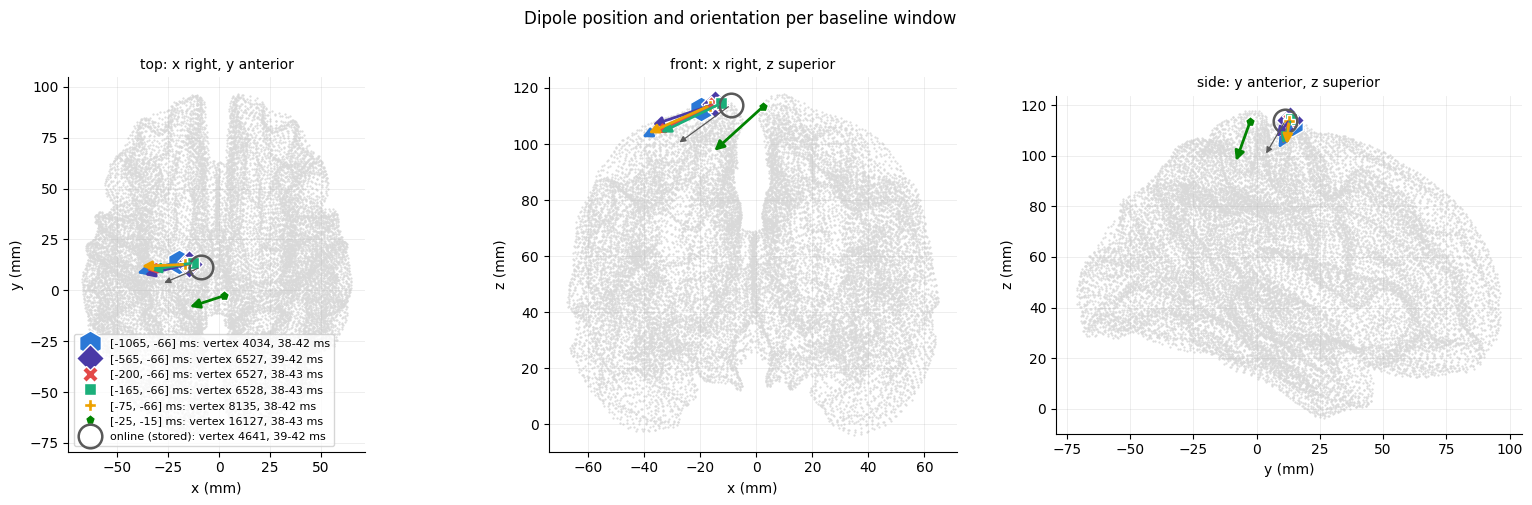

In [11]:
VIEWS = [(0, 1, "top: x right, y anterior"), (0, 2, "front: x right, z superior"), (1, 2, "side: y anterior, z superior")]


def save_fig(fig, name):
    if SAVE_FIGURES:
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def draw_dipoles(axes, names, arrow_mm=25):
    for ax, (h, v, title) in zip(axes, VIEWS):
        ax.scatter(SOURCE_RR[:, h], SOURCE_RR[:, v], s=0.3, color="0.85", rasterized=True)
        for name in names:
            d, st = DIPOLES[name], SOURCE_STYLE[name]
            p, o = d["position_mm"], d["orientation"] * arrow_mm
            ring = name == "online" and len(names) > 1        # online on top: a ring and a thin arrow
            ax.annotate("", xy=(p[h] + o[h], p[v] + o[v]), xytext=(p[h], p[v]),
                        arrowprops=dict(arrowstyle="-|>", color=st["color"], lw=0.9 if ring else 2,
                                        mutation_scale=9 if ring else 14))
            ax.plot(p[h], p[v], st["marker"], color=st["color"], mfc="none" if ring else st["mfc"],
                    mec=st["color"] if ring else "white", ms=17 if ring else MARKER_SIZE.get(name, 10),
                    mew=1.8 if ring else 1.0,
                    label=f"{LABEL[name]}: vertex {d['vertex']}, {d['window_ms'][0]:.0f}-{d['window_ms'][1]:.0f} ms")
        ax.set_xlabel(f"{'xyz'[h]} (mm)")
        ax.set_ylabel(f"{'xyz'[v]} (mm)")
        ax.set_title(title, fontsize=10)
        ax.set_aspect("equal")


fig, axes = plt.subplots(1, 3, figsize=(16, 5))
draw_dipoles(axes, DRAW_ORDER)
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Dipole position and orientation per baseline window", y=1.0)
fig.tight_layout()
save_fig(fig, "dipoles_positions")
plt.show()

### 5.2 Time windows

Left: each source's fitted window within the [38, 50] ms search range. Right: the calibration evoked response
seen through each source's own dipole (free-orientation amplitude at its vertex, as `fit_trial()` computes it per
sample), with the fitted window drawn thick. The shaded band at the start is the tapered artifact window.

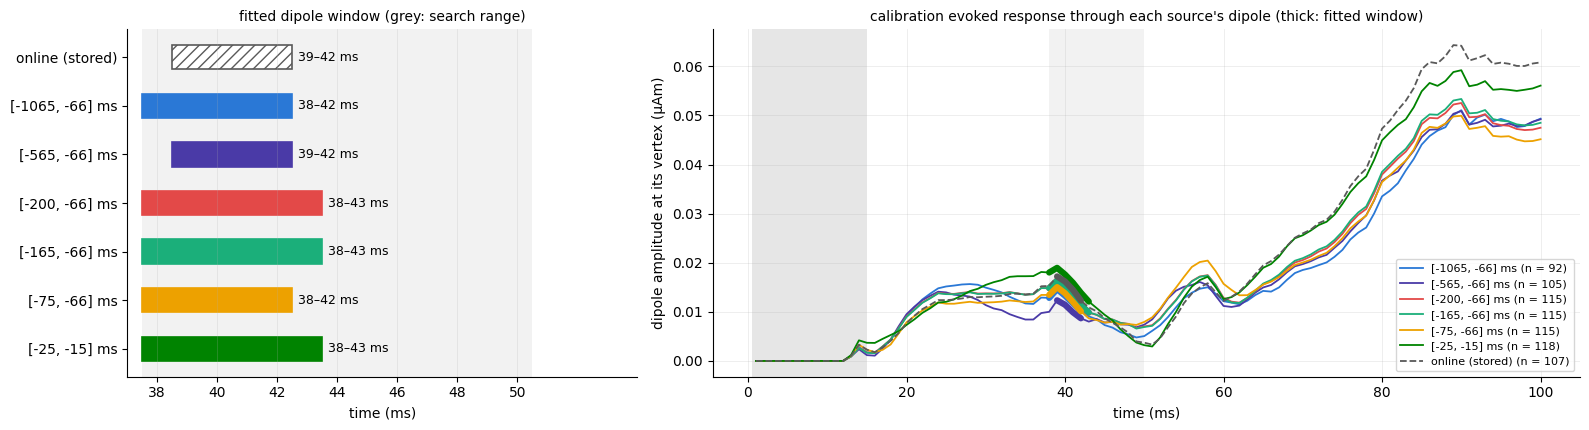

In [12]:
def dipole_waveform(src):
    # free-orientation dipole amplitude at the source's vertex, for every sample of the calibration evoked response
    evoked = CAL_EP[src].mean(axis=0)
    evoked = evoked - evoked.mean(axis=0)
    return np.linalg.norm(SRC[src]["pinv"] @ evoked, axis=0)


fig, axes = plt.subplots(1, 2, figsize=(16, 4.4), gridspec_kw=dict(width_ratios=[1, 1.7]))
ax = axes[0]
ax.axvspan(DIP_TMIN * 1e3 - 0.5, DIP_TMAX * 1e3 + 0.5, color="0.95", lw=0, zorder=0)
for i, src in enumerate(SOURCES[::-1]):
    d, st = DIPOLES[src], SOURCE_STYLE[src]
    w0, w1 = d["window_ms"]
    ax.barh(i, w1 - w0 + 1, left=w0 - 0.5, height=0.5, color=st["color"] if src != "online" else "white",
            edgecolor=st["color"], hatch="///" if src == "online" else None, lw=1.2)
    ax.text(w1 + 0.7, i, f"{w0:.0f}–{w1:.0f} ms", va="center", fontsize=9)
ax.set_yticks(range(len(SOURCES)))
ax.set_yticklabels([LABEL[s] for s in SOURCES[::-1]])
ax.set_xlim(DIP_TMIN * 1e3 - 1, DIP_TMAX * 1e3 + 4)
ax.set_xticks(np.arange(DIP_TMIN * 1e3, DIP_TMAX * 1e3 + 1, 2))
ax.set_xlabel("time (ms)")
ax.set_title("fitted dipole window (grey: search range)", fontsize=10)
ax.grid(axis="y", visible=False)

ax = axes[1]
ax.axvspan(TIMES_MS[0] - 0.5, TAPER_END * 1e3, color="0.9", lw=0, zorder=0)
ax.axvspan(DIP_TMIN * 1e3, DIP_TMAX * 1e3, color="0.95", lw=0, zorder=0)
for src in DRAW_ORDER:
    st, wf = SOURCE_STYLE[src], dipole_waveform(src)
    s, e = DIPOLES[src]["index_range"]
    idx = np.arange(DIP_IDX.start + s, DIP_IDX.start + e)
    ax.plot(TIMES_MS, wf, color=st["color"], ls=st["ls"], lw=1.3, label=f"{LABEL[src]} (n = {len(CAL_EP[src])})")
    ax.plot(TIMES_MS[idx], wf[idx], color=st["color"], lw=4.5, solid_capstyle="round")
ax.set_xlabel("time (ms)")
ax.set_ylabel("dipole amplitude at its vertex (µAm)")
ax.set_title("calibration evoked response through each source's dipole (thick: fitted window)", fontsize=10)
ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "dipoles_windows")
plt.show()

## 6 · Dipoles compared with the online dipole

### 6.1 Differences

For each candidate against the stored online dipole: distance between the vertices, angle between the
orientations, the fitted windows, the correlation of the two dipoles' scalp patterns (their leadfield
topographies; two vertices 20 mm apart can still project almost the same map), and the Spearman ρ of single-trial
amplitudes on the calibration trials both keep. ρ is how much the ranking of trials changes, which is what the
normaliser's labels and PRIME's training follow. Saved as `dipoles_vs_online.csv`.

In [13]:
def angle_deg(a, b):
    return float(np.degrees(np.arccos(np.clip(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)), -1, 1))))


def scalp_pattern(src):
    return SRC[src]["Lp"] @ DIPOLES[src]["orientation"]


def shared_rho(tab, tab_online, key):
    both = tab[tab.kept][[key, "amplitude"]].merge(tab_online[tab_online.kept][[key, "amplitude"]], on=key,
                                                   suffixes=("", "_online")).dropna()
    if len(both) < 4:
        return np.nan, len(both)
    return float(stats.spearmanr(both.amplitude, both.amplitude_online)[0]), len(both)


on = DIPOLES["online"]
rows = []
for src in CANDS:
    d = DIPOLES[src]
    (s, e), (so, eo) = d["index_range"], on["index_range"]
    rho_cal, n_cal = shared_rho(CAL_TAB[src].assign(kept=True), CAL_TAB["online"].assign(kept=True), "trial")
    rows.append({"candidate": LABEL[src], "vertex": d["vertex"], "online vertex": on["vertex"],
                 "distance (mm)": float(np.linalg.norm(d["position_mm"] - on["position_mm"])),
                 "orientation angle (°)": angle_deg(d["orientation"], on["orientation"]),
                 "window (ms)": f"{d['window_ms'][0]:.0f}-{d['window_ms'][1]:.0f}",
                 "online window (ms)": f"{on['window_ms'][0]:.0f}-{on['window_ms'][1]:.0f}",
                 "window start shift (ms)": d["window_ms"][0] - on["window_ms"][0],
                 "shared window samples": max(0, min(e, eo) - max(s, so)),
                 "scalp pattern r": float(np.corrcoef(scalp_pattern(src), scalp_pattern("online"))[0, 1]),
                 "amplitude ρ, calibration": rho_cal, "calibration trials (both keep)": n_cal})
DIPOLE_VS_ONLINE = pd.DataFrame(rows).set_index("candidate")
display(DIPOLE_VS_ONLINE.round(3))
DIPOLE_VS_ONLINE.to_csv(OUT_DIR / "dipoles_vs_online.csv")

,vertex,online vertex,distance (mm),orientation angle (°),window (ms),online window (ms),window start shift (ms),shared window samples,scalp pattern r,"amplitude ρ, calibration",calibration trials (both keep)
candidate,,,,,,,,,,,
"[-1065, -66] ms",4034,4641,10.978,11.560,38-42,39-42,-1.0,4,0.975,0.326,87
"[-565, -66] ms",6527,4641,5.971,17.712,39-42,39-42,0.0,4,0.959,0.332,97
"[-200, -66] ms",6527,4641,5.971,15.647,38-43,39-42,-1.0,4,0.964,0.408,106
"[-165, -66] ms",6528,4641,4.173,14.689,38-43,39-42,-1.0,4,0.969,0.387,106
"[-75, -66] ms",8135,4641,7.541,20.673,38-42,39-42,-1.0,4,0.937,0.305,105
"[-25, -15] ms",16127,4641,18.158,8.027,38-43,39-42,-1.0,4,0.969,0.960,105


### 6.2 Bootstrap stability

Each source's dipole is refitted on `N_BOOT` resamples (with replacement) of its own surviving calibration
trials, with the online procedure: `dipoles_for_indices()` → `determine_optimal_index_range()` →
`determine_optimal_ori_and_pos()`. The spread shows how far a dipole moves through resampling alone. Each
candidate's distance to the online dipole is then placed among the online dipole's own resampling distances:
a candidate beyond most of them has moved further than resampling can explain.

`dipoles_for_indices()` recomputes the leadfield pseudo-inverses and scans the source space sample by sample,
about a second per fit. Here the pseudo-inverses are computed once and the scan covers all samples at once; the
best positions are then scored with the online arithmetic, so the same position wins. The refit on all trials is
checked against each source's dipole first. Saved as `dipole_bootstrap.csv` (one row per resample) and
`dipole_bootstrap_summary.csv`.

In [14]:
class DipoleScan:
    # dipoles_for_indices() of dipole_fitter.py, faster. The leadfield pseudo-inverses are computed once, and the R²
    # of every source position is computed for all samples at once through the projection identity
    # ||L pinv(L) y||² = (L'y)·(pinv(L) y). The positions within 1e-4 of the best are then scored with the online
    # arithmetic, so the chosen position is the one dipoles_for_indices() chooses.
    def __init__(self, forward):
        L = forward["sol"]["data"] - np.mean(forward["sol"]["data"], axis=0)    # average-reference leadfield
        self.n_pos = L.shape[1] // 3
        self.L3 = L.reshape(L.shape[0], self.n_pos, 3).transpose(1, 0, 2)       # (n_pos, n_ch, 3)
        self.pinv = np.linalg.pinv(self.L3)                                      # (n_pos, 3, n_ch)
        self.pinv2d = self.pinv.reshape(self.n_pos * 3, -1)
        self.Lt2d = np.ascontiguousarray(self.L3.transpose(0, 2, 1)).reshape(self.n_pos * 3, -1)
        self.rr = forward["source_rr"]

    def dipoles(self, evoked):
        data = evoked - np.mean(evoked, axis=0)
        n_t = data.shape[1]
        Q = (self.pinv2d @ data).reshape(self.n_pos, 3, n_t)
        approx = ((self.Lt2d @ data).reshape(self.n_pos, 3, n_t) * Q).sum(axis=1) / (data ** 2).sum(axis=0)
        out = []
        for index in range(n_t):
            y = data[:, index]
            near = np.flatnonzero(approx[:, index] >= approx[:, index].max() - 1e-4)
            q = self.pinv[near] @ y                                              # as dipoles_for_indices()
            ypred = np.einsum("nij,nj->ni", self.L3[near], q)
            r2 = np.einsum("ni,ni->n", ypred, ypred) / np.dot(y, y)
            k = int(np.argmax(r2))
            best, amplitude = int(near[k]), float(np.linalg.norm(q[k]))
            out.append({"amplitude": amplitude, "orientation": q[k] / amplitude, "position": self.rr[best],
                        "index": index, "position_index": best, "moment": q[k], "r2": float(r2[k]),
                        "data_predicted": ypred[k]})
        return out

    def fit(self, dipole_buffers, fitter):
        # DipoleFitter.calibrate() without the single-trial fits
        dipoles = self.dipoles(np.mean(dipole_buffers, axis=0))
        index_range, in_range = determine_optimal_index_range(
            dipoles, fitter._min_window_size, fitter._max_window_size, fitter._window_size_exponent)
        position_index, orientation = determine_optimal_ori_and_pos(in_range, fitter._forward)
        return {"position_index": position_index, "orientation": orientation, "index_range": index_range}


if N_BOOT > 0:
    SCAN = DipoleScan(SRC["online"]["fitter"]._forward)
    for src in SOURCES:
        info, ref = SCAN.fit(SRC[src]["dipole_buffers"], SRC[src]["fitter"]), SRC[src]["fitting_info"]
        same = (int(info["position_index"]) == int(ref["position_index"])
                and tuple(info["index_range"]) == tuple(ref["index_range"])
                and np.allclose(info["orientation"], ref["orientation"], atol=1e-8))
        print(f"{LABEL[src]:18s} refit on all its calibration trials reproduces its dipole: {same}")

    rng, rows, t0 = np.random.default_rng(BOOT_SEED), [], time.time()
    for src in SOURCES:
        db = SRC[src]["dipole_buffers"]
        for b in range(N_BOOT):
            info = SCAN.fit(db[rng.integers(0, len(db), len(db))], SRC[src]["fitter"])
            v, (s, e) = int(info["position_index"]), info["index_range"]
            rows.append({"source": LABEL[src], "resample": b, "vertex": v, "x (mm)": SOURCE_RR[v, 0],
                         "y (mm)": SOURCE_RR[v, 1], "z (mm)": SOURCE_RR[v, 2],
                         "orientation x": info["orientation"][0], "orientation y": info["orientation"][1],
                         "orientation z": info["orientation"][2],
                         "window start (ms)": DIP_TMIN * 1e3 + s, "window end (ms)": DIP_TMIN * 1e3 + e - 1})
    BOOT = pd.DataFrame(rows)
    BOOT.to_csv(OUT_DIR / "dipole_bootstrap.csv", index=False)
    print(f"{N_BOOT} resamples x {len(SOURCES)} sources in {time.time() - t0:.0f} s")

    def boot_distances(src, to_src=None):
        b = BOOT[BOOT.source == LABEL[src]]
        ref = DIPOLES[to_src or src]
        return np.linalg.norm(b[["x (mm)", "y (mm)", "z (mm)"]].to_numpy() - ref["position_mm"], axis=1)

    rows = []
    for src in SOURCES:
        b, d = BOOT[BOOT.source == LABEL[src]], DIPOLES[src]
        dist = boot_distances(src)
        ori = b[["orientation x", "orientation y", "orientation z"]].to_numpy()
        ang = [angle_deg(o, d["orientation"]) for o in ori]
        same_window = (b["window start (ms)"] == d["window_ms"][0]) & (b["window end (ms)"] == d["window_ms"][1])
        row = {"source": LABEL[src], "trials": len(SRC[src]["dipole_buffers"]),
               "same vertex (%)": 100 * float((b.vertex == d["vertex"]).mean()),
               "distance to own dipole: median (mm)": float(np.median(dist)),
               "distance to own dipole: 95th pct (mm)": float(np.percentile(dist, 95)),
               "orientation change: median (°)": float(np.median(ang)),
               "same window (%)": 100 * float(same_window.mean())}
        if src != "online":
            shift = float(np.linalg.norm(d["position_mm"] - DIPOLES["online"]["position_mm"]))
            row["distance to online (mm)"] = shift
            row["online resamples closer to online than this (%)"] = 100 * float(np.mean(boot_distances("online") < shift))
        rows.append(row)
    BOOT_SUMMARY = pd.DataFrame(rows).set_index("source")
    display(BOOT_SUMMARY.round(1))
    BOOT_SUMMARY.to_csv(OUT_DIR / "dipole_bootstrap_summary.csv")
else:
    print("N_BOOT = 0: bootstrap skipped")

online (stored)    refit on all its calibration trials reproduces its dipole: True
[-1065, -66] ms    refit on all its calibration trials reproduces its dipole: True
[-565, -66] ms     refit on all its calibration trials reproduces its dipole: True
[-200, -66] ms     refit on all its calibration trials reproduces its dipole: True
[-165, -66] ms     refit on all its calibration trials reproduces its dipole: True
[-75, -66] ms      refit on all its calibration trials reproduces its dipole: True
[-25, -15] ms      refit on all its calibration trials reproduces its dipole: True
200 resamples x 7 sources in 31 s


,trials,same vertex (%),distance to own dipole: median (mm),distance to own dipole: 95th pct (mm),orientation change: median (°),same window (%),distance to online (mm),online resamples closer to online than this (%)
source,,,,,,,,
online (stored),107,2.0,12.9,21.6,10.8,5.5,NaN,NaN
"[-1065, -66] ms",92,6.0,5.6,31.4,7.6,33.0,11.0,37.5
"[-565, -66] ms",105,11.0,5.0,16.6,8.4,11.0,6.0,32.5
"[-200, -66] ms",115,22.5,2.6,6.6,5.9,26.5,6.0,32.5
"[-165, -66] ms",115,15.5,2.8,16.3,5.9,35.0,4.2,27.5
"[-75, -66] ms",115,9.5,4.0,18.5,6.8,33.5,7.5,36.5
"[-25, -15] ms",118,2.5,14.9,23.4,9.6,29.5,18.2,75.0


Resampled dipole positions (small dots) around each source's dipole (large marker).

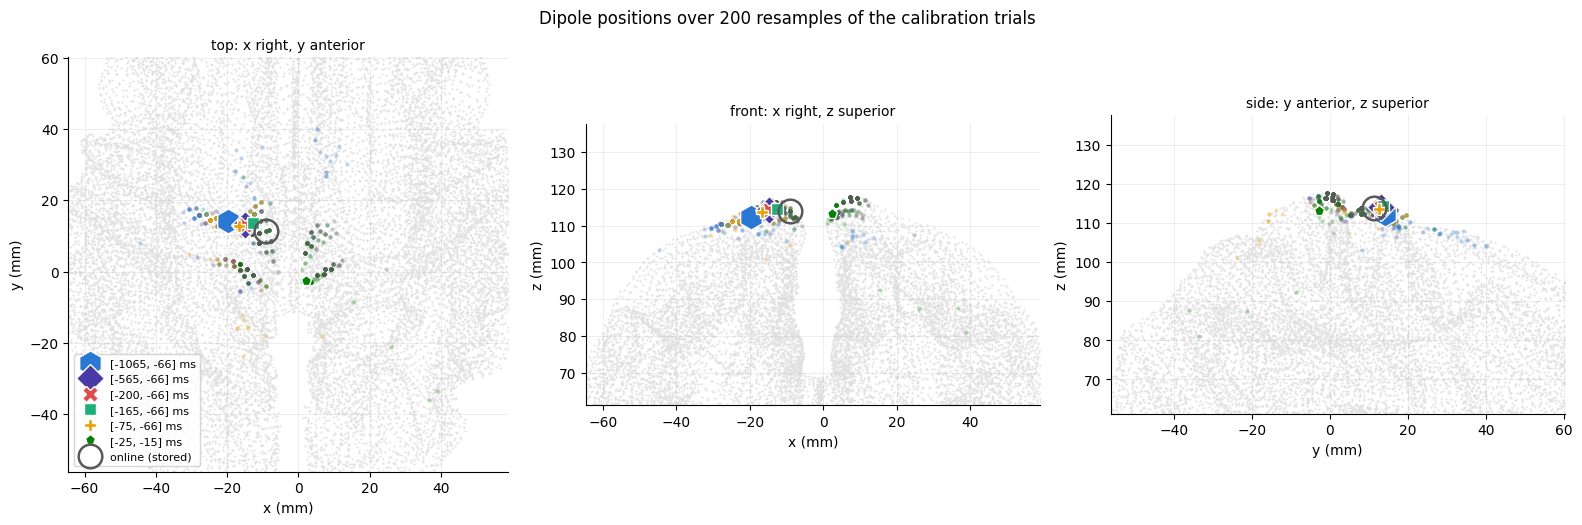

In [15]:
if N_BOOT > 0:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    for ax, (h, v, title) in zip(axes, VIEWS):
        ax.scatter(SOURCE_RR[:, h], SOURCE_RR[:, v], s=0.3, color="0.88", rasterized=True)
        for src in DRAW_ORDER:
            st, b, d = SOURCE_STYLE[src], BOOT[BOOT.source == LABEL[src]], DIPOLES[src]
            cols = ["x (mm)", "y (mm)", "z (mm)"]
            ax.scatter(b[cols[h]], b[cols[v]], s=10, color=st["color"], alpha=0.25, lw=0)
            ring = src == "online"
            ax.plot(d["position_mm"][h], d["position_mm"][v], st["marker"], color=st["color"],
                    mfc="none" if ring else st["mfc"], mec=st["color"] if ring else "white",
                    ms=17 if ring else MARKER_SIZE.get(src, 10), mew=1.8 if ring else 1.0, label=LABEL[src])
        ax.set_xlabel(f"{'xyz'[h]} (mm)")
        ax.set_ylabel(f"{'xyz'[v]} (mm)")
        ax.set_title(title, fontsize=10)
        ax.set_aspect("equal")
        pts = BOOT[["x (mm)", "y (mm)", "z (mm)"]].to_numpy()
        ax.set_xlim(pts[:, h].min() - 20, pts[:, h].max() + 20)
        ax.set_ylim(pts[:, v].min() - 20, pts[:, v].max() + 20)
    axes[0].legend(fontsize=8, loc="lower left")
    fig.suptitle(f"Dipole positions over {N_BOOT} resamples of the calibration trials", y=1.0)
    fig.tight_layout()
    save_fig(fig, "dipoles_bootstrap")
    plt.show()

## 7 · Sensor-space TEPs of the calibration block

The epochs are the [1, 100] ms output of each source's whole post chain, what the dipole fit sees: baseline →
artifact taper → bad-channel interpolation → average reference → ICA → baseline → SOUND → SSP-SIR → taper →
average reference. Each source averages its own surviving calibration trials (the trials its dipole was fitted
on), so the TEPs differ through the baseline, through the filters fitted on the baselined data (SOUND, SSP-SIR)
and through which trials survive. Amplitudes are in the units of the acquisition stream (µV scale,
uncalibrated). The first 15 ms are tapered towards zero (dark band); the light band is the dipole search window.

Four figures: butterflies (one panel per source, its own dipole window tinted); GMFA and Cz; the left-M1 ROI
(mean, then each channel; channels interpolated as bad channels are marked); topographies of the mean over
`TOPO_WINDOW` and over each source's own dipole window, on one colour scale (black rings: ROI channels). The
evoked responses are saved as `tep_evoked.npz`, the curves as `tep_curves.csv`.

In [16]:
ROI_IDX = [CH_NAMES.index(c) for c in ROI_CHANNELS]
CH_IDX = CH_NAMES.index(SINGLE_CHANNEL)
TOPO_IDX = slice(int(round((TOPO_WINDOW[0] - POST_TMIN) * PROC_SFREQ)),
                 int(round((TOPO_WINDOW[1] - POST_TMIN) * PROC_SFREQ)) + 1)
TOPO_INFO = SRC["online"]["pp"]._info_processed
BAD = {src: {str(c) for c in SRC[src]["bundle"]["bad_channels"]} for src in SOURCES}
EVOKED, CURVES = {}, []


def interpolated_note(channels):
    # which of these channels the sources interpolated as bad channels
    everywhere = [ch for ch in channels if all(ch in BAD[s] for s in SOURCES)]
    notes = [", ".join(everywhere) + " interpolated"] if everywhere else []
    for ch in channels:
        where = [LABEL[s] for s in SOURCES if ch in BAD[s]]
        if where and len(where) < len(SOURCES):
            notes.append(f"{ch} interpolated in {', '.join(where)}")
    return "; ".join(notes)


def channel_title(ch):
    where = [s for s in SOURCES if ch in BAD[s]]
    if not where:
        return ch
    if len(where) == len(SOURCES):
        return f"{ch} (interpolated)"
    return f"{ch} (interpolated in {', '.join(LABEL[s] for s in where)})"


def shade(ax):
    ax.axvspan(TIMES_MS[0] - 0.5, TAPER_END * 1e3, color="0.88", lw=0, zorder=0)    # tapered artifact window
    ax.axvspan(DIP_TMIN * 1e3, DIP_TMAX * 1e3, color="0.95", lw=0, zorder=0)        # dipole search window


def own_window(src):
    s, e = DIPOLES[src]["index_range"]
    return slice(DIP_IDX.start + s, DIP_IDX.start + e)


def tep_figures(key, title, epochs):
    srcs = [s for s in SOURCES if len(epochs[s])]
    ev = {s: epochs[s].mean(axis=0) for s in srcs}
    n = {s: len(epochs[s]) for s in srcs}
    EVOKED[key] = (ev, n)
    for s in srcs:
        CURVES.append(pd.DataFrame({"trial set": key, "source": LABEL[s], "trials": n[s], "time (ms)": TIMES_MS,
                                    "GMFA": ev[s].std(axis=0), "ROI mean": ev[s][ROI_IDX].mean(axis=0),
                                    **{ch: ev[s][CH_NAMES.index(ch)] for ch in ROI_CHANNELS + [SINGLE_CHANNEL]}}))
    draw = [s for s in DRAW_ORDER if s in ev]

    # butterflies
    fig, axes = plt.subplots(1, len(srcs), figsize=(3.4 * len(srcs), 3.6), sharey=True, squeeze=False)
    for ax, s in zip(axes[0], srcs):
        st = SOURCE_STYLE[s]
        shade(ax)
        w = own_window(s)
        ax.axvspan(TIMES_MS[w][0] - 0.5, TIMES_MS[w][-1] + 0.5, color=st["color"], alpha=0.18, lw=0, zorder=0)
        ax.plot(TIMES_MS, ev[s].T, color=st["color"], lw=0.6, alpha=0.8)
        ax.set_title(f"{LABEL[s]}\nn = {n[s]}", fontsize=10)
        ax.set_xlabel("time (ms)")
    axes[0][0].set_ylabel("amplitude (µV, uncalibrated)")
    fig.suptitle(f"{title}: all channels", y=1.03)
    fig.tight_layout()
    save_fig(fig, f"tep_{key}_butterfly")
    plt.show()

    # GMFA and the single channel
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.9))
    for s in draw:
        st = SOURCE_STYLE[s]
        axes[0].plot(TIMES_MS, ev[s].std(axis=0), color=st["color"], ls=st["ls"], lw=1.8, label=f"{LABEL[s]} (n = {n[s]})")
        axes[1].plot(TIMES_MS, ev[s][CH_IDX], color=st["color"], ls=st["ls"], lw=1.8)
    axes[0].set(title="global mean field amplitude (GMFA)", ylabel="µV (uncalibrated)", xlabel="time (ms)")
    axes[1].set(title=channel_title(SINGLE_CHANNEL), ylabel="µV (uncalibrated)", xlabel="time (ms)")
    for ax in axes:
        shade(ax)
    axes[0].legend(fontsize=8)
    fig.suptitle(f"{title}: GMFA and {SINGLE_CHANNEL}", y=1.02)
    fig.tight_layout()
    save_fig(fig, f"tep_{key}_gmfa_{SINGLE_CHANNEL}")
    plt.show()

    # left-M1 ROI: mean, then each channel
    panels = [("ROI mean (" + ", ".join(ROI_CHANNELS) + ")", ROI_IDX)] + [(ch, [CH_NAMES.index(ch)]) for ch in ROI_CHANNELS]
    ncol = 4
    nrow = int(np.ceil((len(panels) + 1) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 3.3 * nrow), sharex=True, sharey=True, squeeze=False)
    for ax, (name, idx) in zip(axes.flat, panels):
        shade(ax)
        for s in draw:
            st = SOURCE_STYLE[s]
            ax.plot(TIMES_MS, ev[s][idx].mean(axis=0), color=st["color"], ls=st["ls"], lw=2.2 if len(idx) > 1 else 1.6)
        if len(idx) > 1:
            note = interpolated_note(ROI_CHANNELS)
            ax.set_title(f"{name}\n{note}" if note else name, fontsize=9)
        else:
            ax.set_title(channel_title(name), fontsize=10)
    for ax in axes.flat[len(panels):]:
        ax.axis("off")
    handles = [Line2D([], [], color=SOURCE_STYLE[s]["color"], ls=SOURCE_STYLE[s]["ls"], lw=2, label=f"{LABEL[s]} (n = {n[s]})")
               for s in srcs]
    axes.flat[len(panels)].legend(handles=handles, loc="center", fontsize=9, frameon=False)
    for ax in axes[-1]:
        ax.set_xlabel("time (ms)")
    for ax in axes[:, 0]:
        ax.set_ylabel("µV (uncalibrated)")
    fig.suptitle(f"{title}: left M1 ROI", y=1.01)
    fig.tight_layout()
    save_fig(fig, f"tep_{key}_roi")
    plt.show()

    # topographies: TOPO_WINDOW and each source's own dipole window, one colour scale
    rows_def = [(f"{TOPO_WINDOW[0] * 1e3:.0f}–{TOPO_WINDOW[1] * 1e3:.0f} ms", lambda s: TOPO_IDX),
                ("own dipole window", own_window)]
    maps = {(r, s): ev[s][:, f(s)].mean(axis=1) for r, (_, f) in enumerate(rows_def) for s in srcs}
    vmax = max(float(np.abs(m).max()) for m in maps.values())
    fig, axes = plt.subplots(2, len(srcs), figsize=(2.9 * len(srcs) + 1.2, 6.2), squeeze=False)
    mask = np.isin(CH_NAMES, ROI_CHANNELS)
    for r, (row_title, f) in enumerate(rows_def):
        for c, s in enumerate(srcs):
            ax = axes[r, c]
            im, _ = mne.viz.plot_topomap(maps[(r, s)], TOPO_INFO, axes=ax, show=False, vlim=(-vmax, vmax),
                                         cmap="RdBu_r", contours=6, mask=mask,
                                         mask_params=dict(marker="o", markerfacecolor="none", markeredgecolor="black",
                                                          markeredgewidth=1.0, markersize=5))
            w = TIMES_MS[f(s)]
            ax.set_title(f"{LABEL[s]}\n{w[0]:.0f}–{w[-1]:.0f} ms" if r else f"{LABEL[s]}\n{row_title}", fontsize=9)
    fig.colorbar(im, ax=axes, shrink=0.6, label="µV (uncalibrated)")
    fig.suptitle(f"{title}: topography, top {rows_def[0][0]}, bottom each source's dipole window", y=1.0)
    save_fig(fig, f"tep_{key}_topo")
    plt.show()

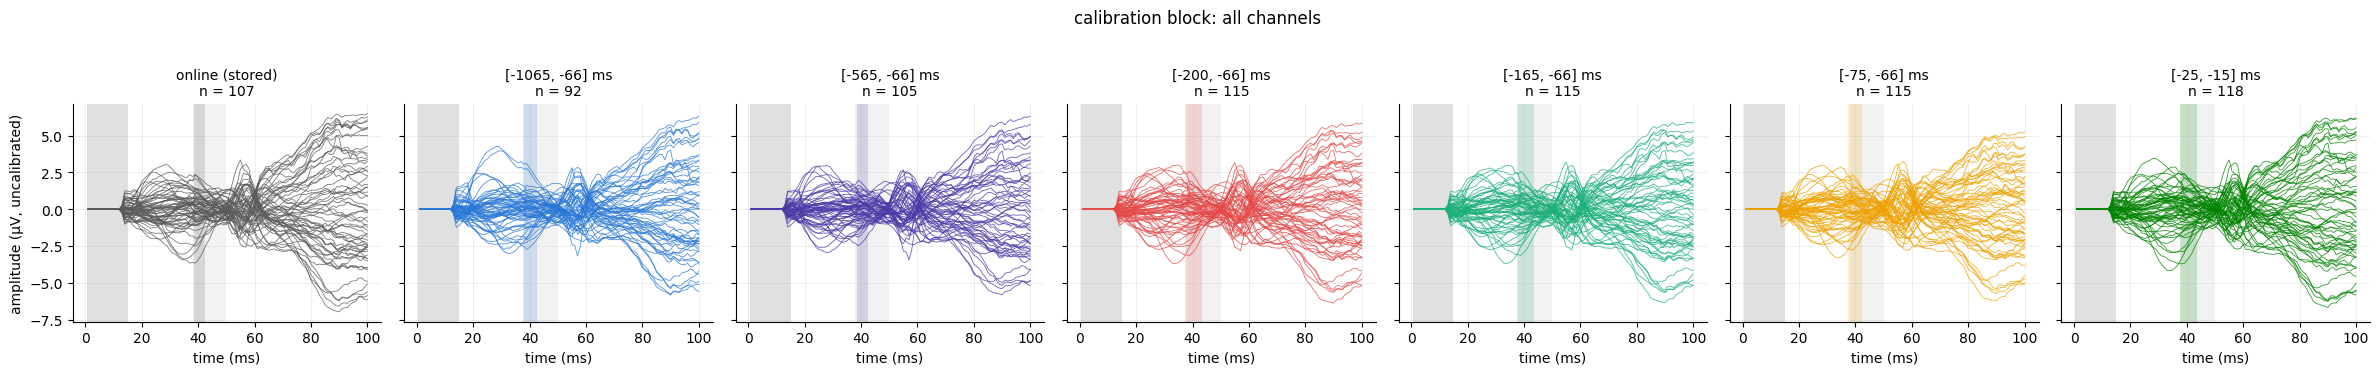

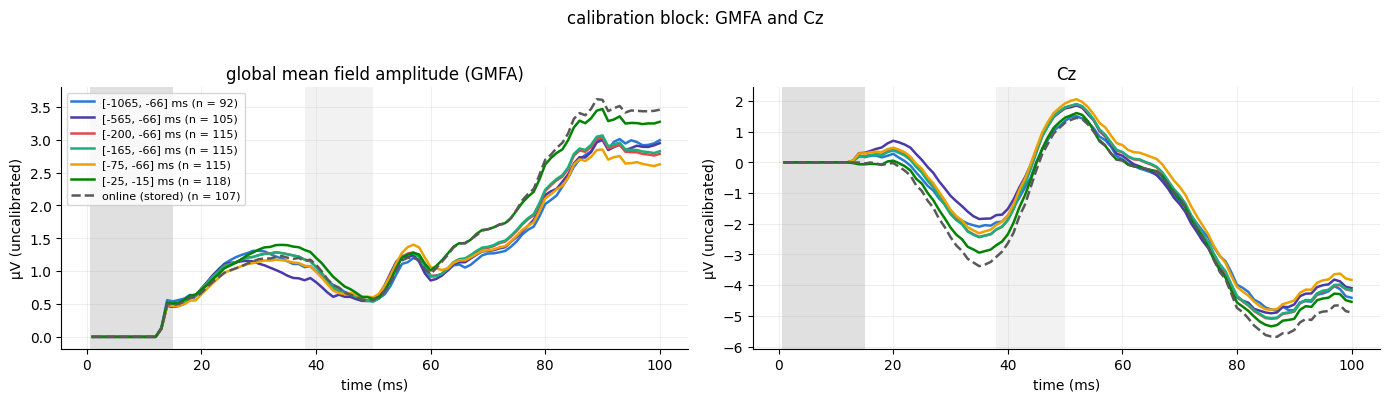

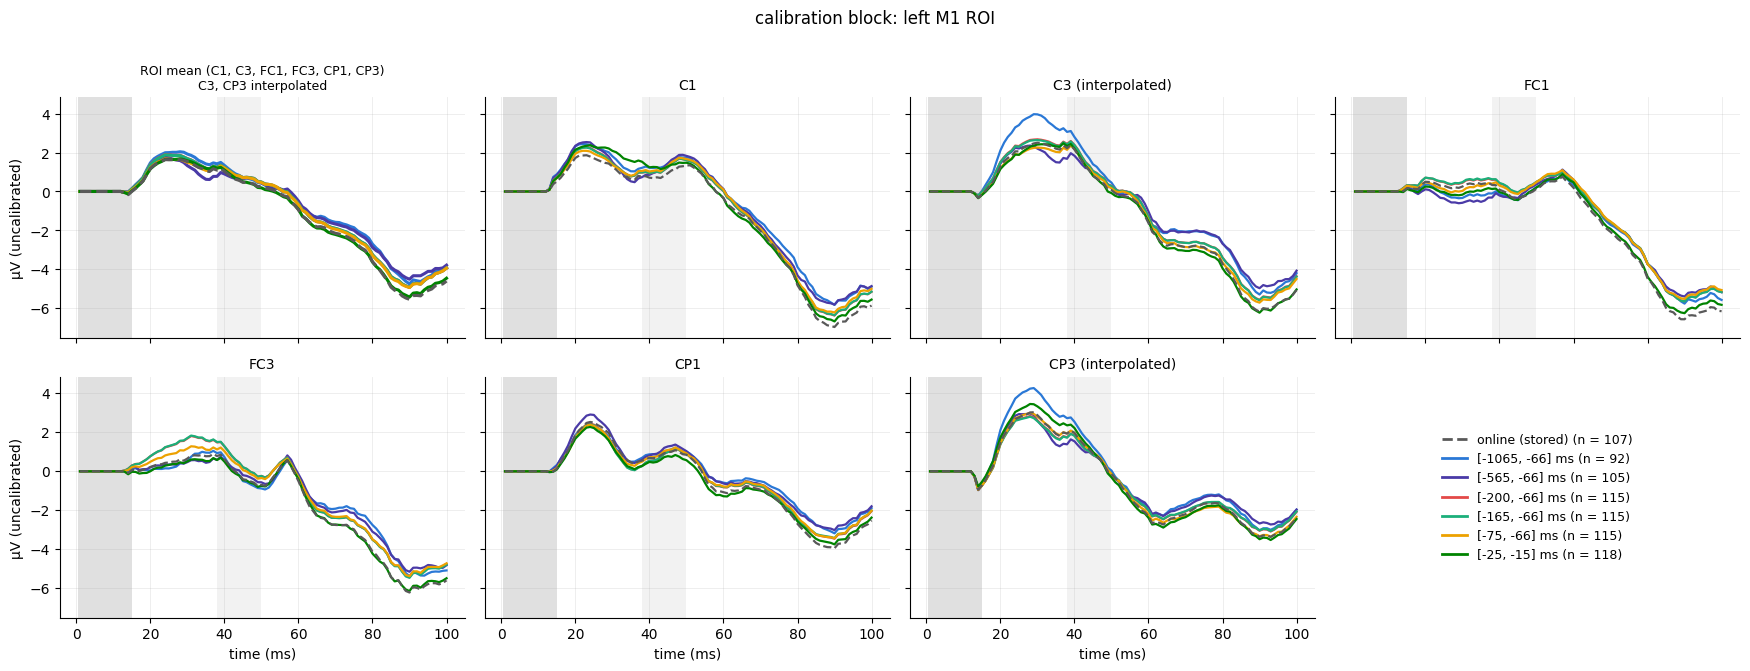

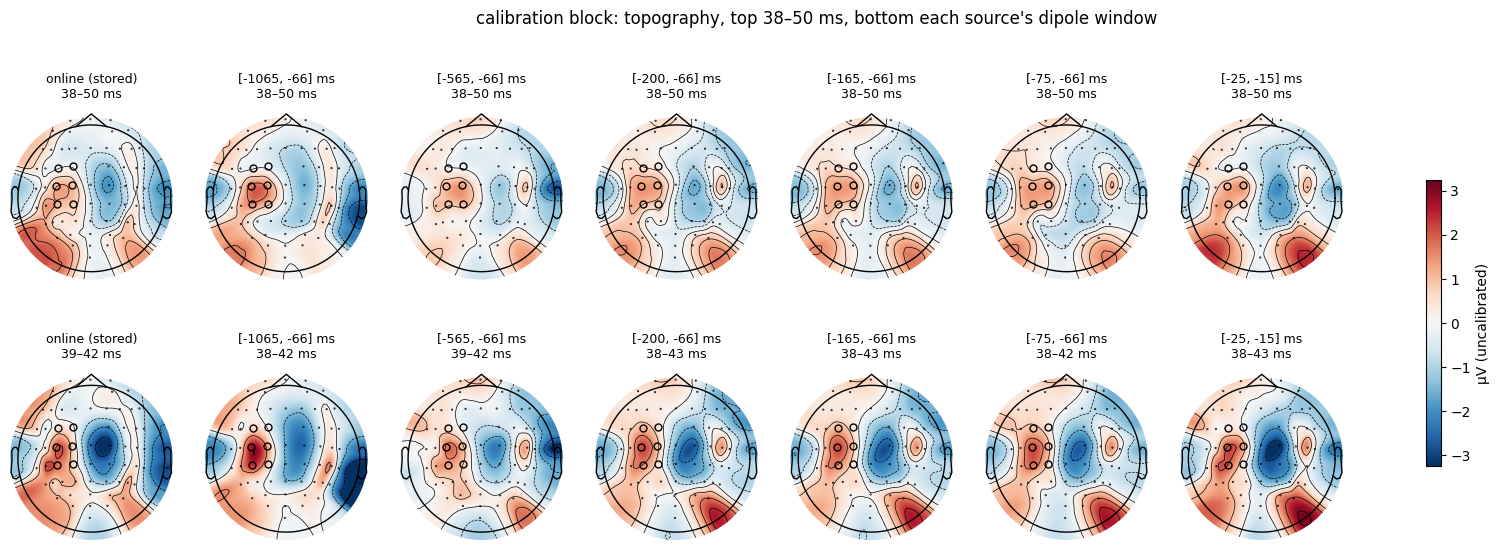

In [17]:
tep_figures("calibration", "calibration block", CAL_EP)

In [18]:
arrays = {"times_ms": TIMES_MS, "ch_names": np.array(CH_NAMES)}
for key, (ev, n) in EVOKED.items():
    for s in ev:
        arrays[f"{key}__{s}"] = ev[s]
        arrays[f"{key}__{s}__n"] = np.array(n[s])
np.savez(OUT_DIR / "tep_evoked.npz", **arrays)
pd.concat(CURVES, ignore_index=True).to_csv(OUT_DIR / "tep_curves.csv", index=False)
print(f"tep_evoked.npz: keys '<trial set>__<source>' ({', '.join(EVOKED)} x {', '.join(SOURCES)}), channels x time")
print(f"tep_curves.csv: GMFA, ROI mean, {', '.join(ROI_CHANNELS + [SINGLE_CHANNEL])} per trial set and source")

tep_evoked.npz: keys '<trial set>__<source>' (calibration x online, -1065_-66, -565_-66, -200_-66, -165_-66, -75_-66, -25_-15), channels x time
tep_curves.csv: GMFA, ROI mean, C1, C3, FC1, FC3, CP1, CP3, Cz per trial set and source


## Summary

In [19]:
print(f"{SUBJECT_ID}, {len(CAL)} calibration trials, candidates on {ms(RAW_WINDOW)}\n")
for src in SOURCES:
    b, d = SRC[src]["bundle"], DIPOLES[src]
    line = (f"{LABEL[src]:18s} kept {len(b['trials_kept']):3d} (ocular {len(b['trials_dropped']['ocular'])}, "
            f"pre MAD {len(b['trials_dropped']['qc'])}, post MAD {len(b['trials_dropped']['post'])}); "
            f"dipole {d['vertex']}, {d['window_ms'][0]:.0f}-{d['window_ms'][1]:.0f} ms, R² {d['r2']:.2f}")
    if src != "online":
        r = DIPOLE_VS_ONLINE.loc[LABEL[src]]
        line += (f"; vs online {r['distance (mm)']:.1f} mm, {r['orientation angle (°)']:.1f}°, "
                 f"scalp r {r['scalp pattern r']:.3f}, amplitude ρ {r['amplitude ρ, calibration']:.2f}")
        if N_BOOT > 0:
            line += (f"; shift larger than {BOOT_SUMMARY.loc[LABEL[src], 'online resamples closer to online than this (%)']:.1f}% "
                     "of the online dipole's resampling shifts")
    print(line)
print(f"\ntables and figures in {OUT_DIR}")
for p in sorted(OUT_DIR.glob("*.*")):
    print(f"  {p.name}")

pilot005, 125 calibration trials, candidates on [-1100, 100] ms

online (stored)    kept 107 (ocular 13, pre MAD 4, post MAD 1); dipole 4641, 39-42 ms, R² 0.61
[-1065, -66] ms    kept  92 (ocular 26, pre MAD 3, post MAD 4); dipole 4034, 38-42 ms, R² 0.48; vs online 11.0 mm, 11.6°, scalp r 0.975, amplitude ρ 0.33; shift larger than 37.5% of the online dipole's resampling shifts
[-565, -66] ms     kept 105 (ocular 14, pre MAD 2, post MAD 4); dipole 6527, 39-42 ms, R² 0.55; vs online 6.0 mm, 17.7°, scalp r 0.959, amplitude ρ 0.33; shift larger than 32.5% of the online dipole's resampling shifts
[-200, -66] ms     kept 115 (ocular 4, pre MAD 4, post MAD 2); dipole 6527, 38-43 ms, R² 0.57; vs online 6.0 mm, 15.6°, scalp r 0.964, amplitude ρ 0.41; shift larger than 32.5% of the online dipole's resampling shifts
[-165, -66] ms     kept 115 (ocular 4, pre MAD 4, post MAD 2); dipole 6528, 38-43 ms, R² 0.57; vs online 4.2 mm, 14.7°, scalp r 0.969, amplitude ρ 0.39; shift larger than 27.5% of the